# **Bar Chart - Demo**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:
pokemon = pd.read_csv('./material/pokemon.csv')
print(pokemon.shape)
pokemon.head(10)

(807, 14)


,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65
5,6,charizard,1,1.7,90.5,240,fire,flying,78,84,78,100,109,85
6,7,squirtle,1,0.5,9.0,63,water,NaN,44,48,65,43,50,64
7,8,wartortle,1,1.0,22.5,142,water,NaN,59,63,80,58,65,80
8,9,blastoise,1,1.6,85.5,239,water,NaN,79,83,100,78,85,105
9,10,caterpie,1,0.3,2.9,39,bug,NaN,45,30,35,45,20,20


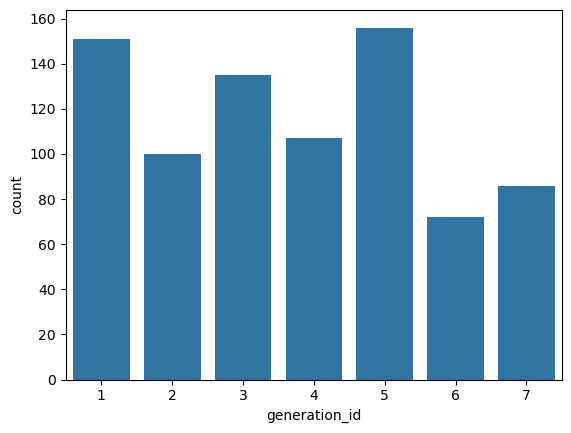

In [4]:
# Present generation_id column in bar chart
sb.countplot(data = pokemon, x = 'generation_id');
plt.show()

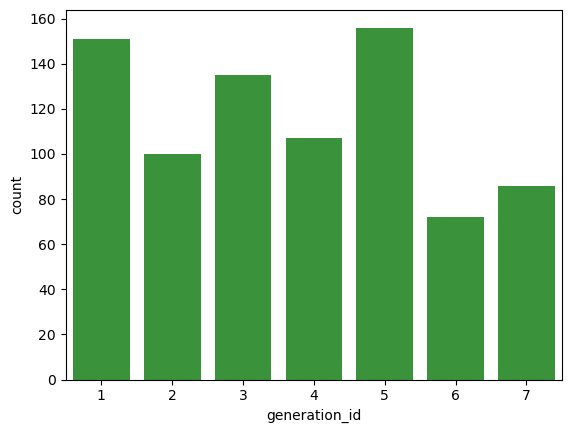

In [ ]:
# It returns a list of RGB tuples representing colors that Seaborn uses by default for categorical data visualization.
sb.color_palette()

# Here we can select the color from the tuple
base_color = sb.color_palette()[2]

# from color attribute we can select which color we need to use in the plot.
sb.countplot(data = pokemon, x = 'generation_id', color = base_color);
plt.show()

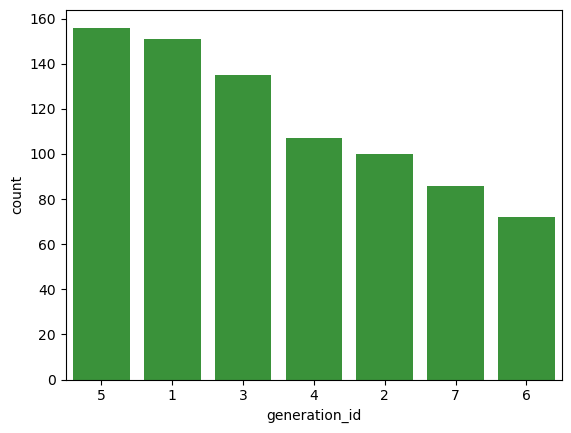

In [19]:
# To control the position of each generation_id in the plot
# We used "order" in countplot 

# Ex1: provide hardcoded list
sb.countplot(data = pokemon, x = 'generation_id', color = base_color, order = [5,1,3,4,2,7,6]);

# returns the unique values (labels) from the value_counts result,
# ordered by frequency (most frequent first by default).
gen_order = pokemon['generation_id'].value_counts().index

sb.countplot(data = pokemon, x = 'generation_id', color = base_color, order = gen_order);



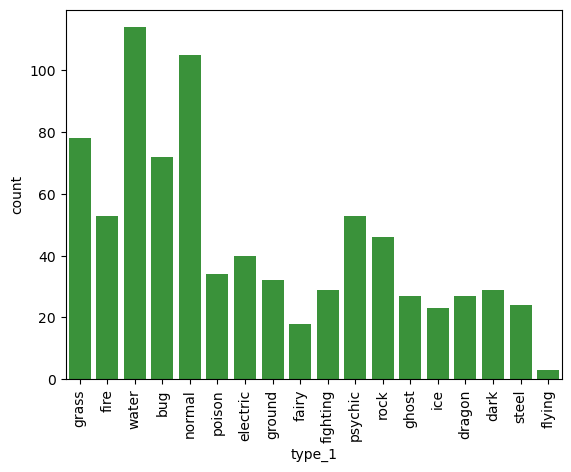

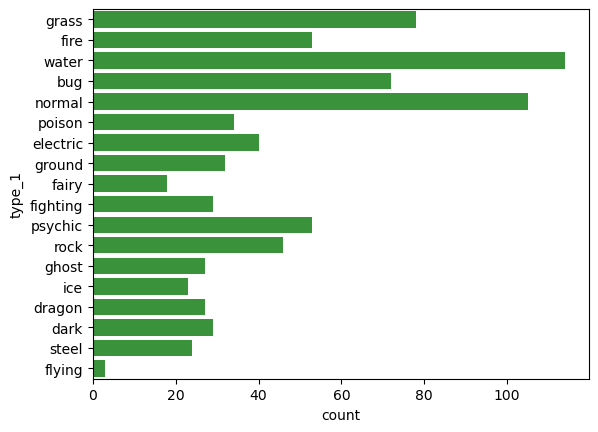

In [24]:
# by plotting this example directly we can observer an overlapping happened between cols names.
sb.countplot(data = pokemon, x = 'type_1', color = base_color);

# to solve that we might need to make cols display vertically
plt.xticks(rotation = 90)
plt.show()

# Or we can move type_1 to be in the y-axis instead of x
sb.countplot(data = pokemon, y = 'type_1', color = base_color);
plt.show()

### **Absolute Vs Relative Frequency**

   id     species type_level   type
0   1   bulbasaur     type_1  grass
1   2     ivysaur     type_1  grass
2   3    venusaur     type_1  grass
3   4  charmander     type_1   fire
4   5  charmeleon     type_1   fire
5   6   charizard     type_1   fire
6   7    squirtle     type_1  water
7   8   wartortle     type_1  water
8   9   blastoise     type_1  water
9  10    caterpie     type_1    bug


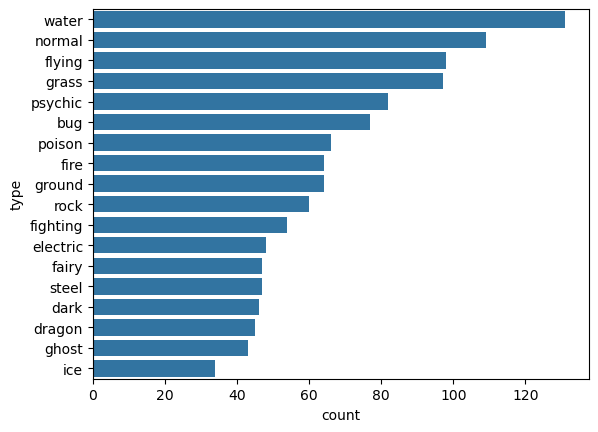

In [ ]:
# Example 1. Demonstrate data wrangling, and plot a horizontal bar chart.

# To show the actual table of Pokemons
# pokemon.head(10)

# pandas.DataFrame.melt() 
# method to unpivot a DataFrame from wide to long format, optionally leaving identifiers set.

# DataFrame.melt(id_vars, value_vars, var_name, value_name, col_level, ignore_index)
# It is essential to understand the parameters involved:
# id_vars - It is a tuple representing the column(s) to use as identifier variables.
# value_vars - It is tuple representing the column(s) to unpivot (remove, out of place).
# var_name - It is a name of the new column.
# value_name - It is a name to use for the ‘value’ of the columns that are unpivoted.
    
pkmn_types = pokemon.melt(id_vars=['id', 'species'], 
                          value_vars=['type_1', 'type_2'], 
                          var_name='type_level', 
                          value_name='type')

print(pkmn_types.head(10))

type_counts = pkmn_types['type'].value_counts()
type_order = type_counts.index

sb.countplot(data=pkmn_types, y='type', color=base_color, order=type_order);

0.10808580858085809


C:\Users\Ahmed Maher\AppData\Local\Temp\ipykernel_30132\944557381.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  max_type_count = type_counts[0]


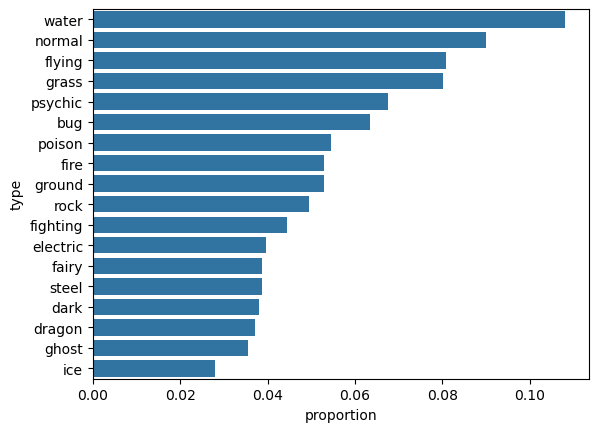

In [42]:
# Example 2. Plot a bar chart having the proportions, instead of the actual count, on one of the axes.
# Returns the sum of all not-null values in `type` column
n_pokemon = pkmn_types['type'].value_counts().sum()

# Return the highest frequency in the `type` column
max_type_count = type_counts[0]

# Return the maximum proportion, or in other words, 
# compute the length of the longest bar in terms of the proportion
max_prop = max_type_count / n_pokemon
print(max_prop)

# Use numpy.arange() function to produce a set of evenly spaced proportioned values 
# between 0 and max_prop, with a step size 2\%
tick_props = np.arange(0, max_prop, 0.02)

# Use a list comprehension to create tick_names that we will apply to the tick labels. 
# Pick each element `v` from the `tick_props`, and convert it into a formatted string.
# `{:0.2f}` denotes that before formatting, we 2 digits of precision and `f` is used to represent floating point number.
# Refer [here](https://docs.python.org/2/library/string.html#format-string-syntax) for more details
tick_names = ['{:0.2f}'.format(v) for v in tick_props]
tick_names

sb.countplot(data=pkmn_types, y='type', color=base_color, order=type_order);
# Change the tick locations and labels
plt.xticks(tick_props * n_pokemon, tick_names)
plt.xlabel('proportion');